# Olist | Penjualan, Pengiriman, dan Pengalaman Pelanggan
Surya Winaldi Yakin · Portofolio Data Analyst

**Pertanyaan.** Di mana keterlambatan terkonsentrasi, berapa nilai produk yang terlibat, dan tahap mana yang layak diperiksa?

Jalankan dari paket proyek. Di Colab, unggah dua CSV dari folder `data/` ke direktori kerja. Tabel dapat dibangun ulang dari arsip Olist menggunakan skrip Python dan SQL dalam paket. Semua periode masuk dalam data. Januari 2017–Agustus 2018 dipakai sebagai pembanding yang konsisten dengan laporan awal.

[Sumber data Olist di Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) · CC BY-NC-SA 4.0

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
from IPython.display import Image, display
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
def read(name):
    file = next((p for p in [root/'data'/name,root/name] if p.is_file()),None)
    if file is None:
        raise FileNotFoundError(f'Letakkan {name} di folder data/ atau direktori kerja.')
    return pd.read_csv(file, encoding='utf-8-sig')
orders = read('Olist_Pesanan_Gabungan.csv')
items = read('Olist_Item_Gabungan.csv')
out = root/'results'
out.mkdir(exist_ok=True)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold',
                     'text.color':'#173936','axes.labelcolor':'#173936','font.size':10})
teal, rust, gold = '#137A72','#B44E38','#CB912F'
def save(fig, name):
    fig.tight_layout()
    path=out/f'{name}.png'
    fig.savefig(path,dpi=155,bbox_inches='tight',facecolor='white')
    plt.close(fig)
    display(Image(filename=str(path)))

## 1. Audit dan definisi
Satuan tabel pesanan adalah satu order. Satuan tabel item adalah satu baris produk dalam order. Nilai uang disimpan dalam centavos. Nilai produk pada pesanan diterima menjumlahkan harga item tanpa ongkir. Pesanan layak ukur memiliki status diterima dan kedua tanggal yang valid. Penerimaan dihitung terlambat jika tanggal kalender aktual melewati tanggal estimasi. Pesanan tanpa informasi yang cukup tetap masuk hitungan pesanan dan dikeluarkan dari penyebut keterlambatan.

In [2]:
assert len(orders)==99441 and orders.order_id.is_unique
assert len(items)==112650 and not items.duplicated(['order_id','item_no']).any()
assert set(items.order_id)<=set(orders.order_id)
assert (items[['item_cents','freight_cents']].sum()==orders[['item_cents','freight_cents']].sum()).all()
assert orders.loc[orders.eligible.eq(0),'late'].isna().all()
assert orders.loc[orders.eligible.eq(1),'late'].isin([0,1]).all()
orders['delivered']=orders.status.eq('delivered')
orders['product_brl']=orders.item_cents.where(orders.delivered,0)/100
orders['late_brl']=orders.item_cents.where(orders.late.eq(1),0)/100
window=orders.month.between('2017-01','2018-08')
def kpis(d):
    return dict(orders=len(d), delivered=int(d.delivered.sum()), eligible=int(d.eligible.sum()),
                late=int(d.late.sum()), gmv=round(d.product_brl.sum(),2),
                late_gmv=round(d.late_brl.sum(),2))
total = { 'full':kpis(orders), 'core':kpis(orders[window]) }
assert [total['core'][k] for k in ['orders','eligible','late','gmv']]==[99092,96203,6531,13181027.13]
display(pd.DataFrame(total).T)

,orders,delivered,eligible,late,gmv,late_gmv
full,99441.0,96478.0,96470.0,6534.0,13221498.11,985924.34
core,99092.0,96211.0,96203.0,6531.0,13181027.13,985618.47


## 2. Skala penjualan dan perubahan bulanan
Bulan didefinisikan dari tanggal pembelian. Bulan tanpa pesanan layak ukur tidak mempunyai persentase keterlambatan. Penjualan kategori asli dihitung pada tabel item dan hanya mencakup item dari pesanan diterima.

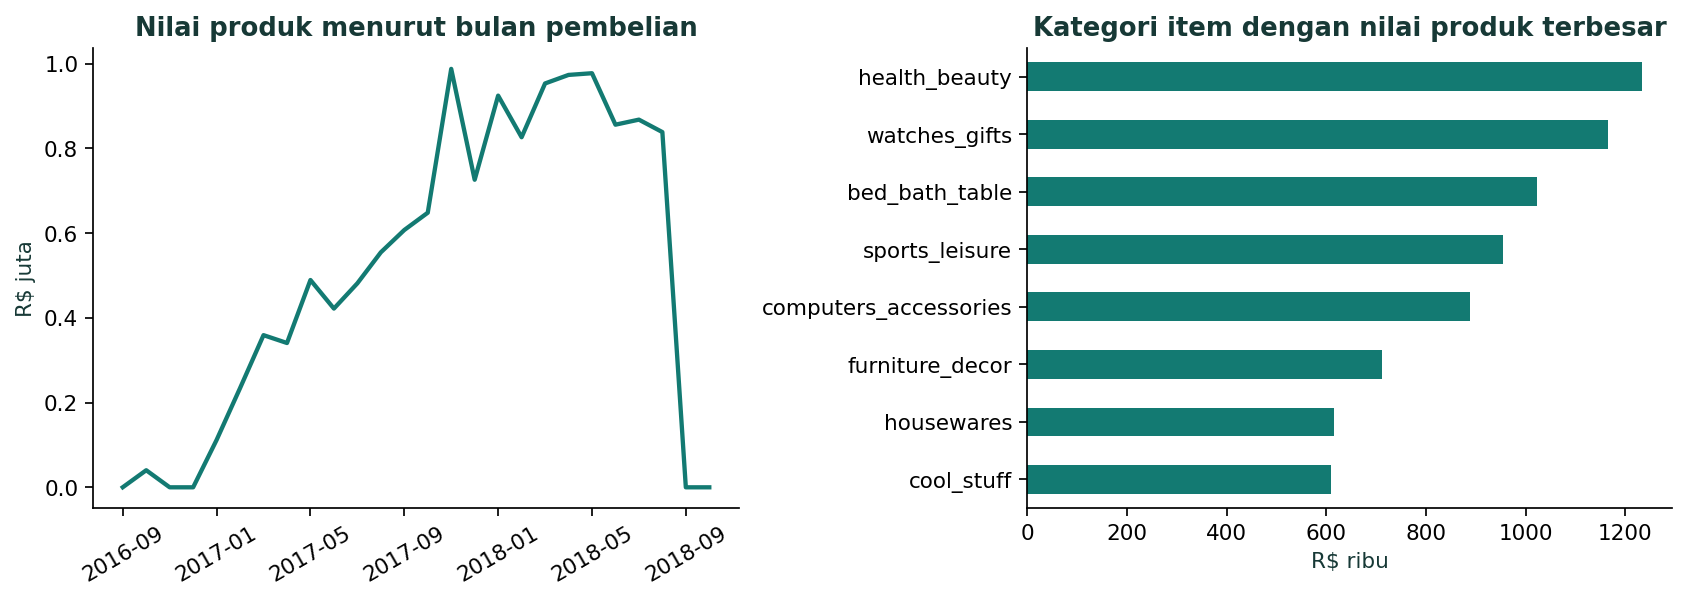

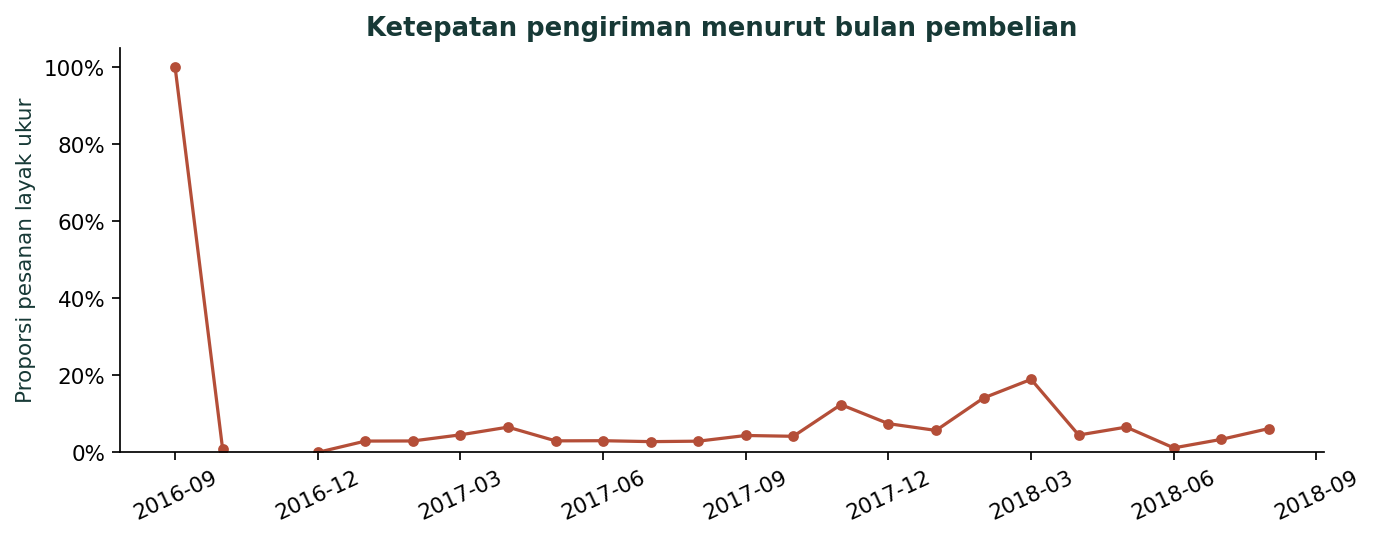

In [3]:
monthly=orders.groupby('month').agg(orders=('order_id','size'),eligible=('eligible','sum'),
                                     late=('late','sum'),gmv=('product_brl','sum'))
monthly=monthly.reindex(pd.period_range(monthly.index.min(),monthly.index.max(),freq='M').astype(str),fill_value=0)
monthly['rate']=monthly.late/monthly.eligible.replace(0,np.nan)
monthly.rename_axis('month').to_csv(out/'monthly.csv')
sold=items[items.order_status.eq('delivered')]
category=sold.groupby('category').item_cents.sum().div(100).sort_values(ascending=False)
assert np.isclose(category.sum(),total['full']['gmv'])
category.rename('product_brl').to_csv(out/'category_sales.csv')
fig,ax=plt.subplots(1,2,figsize=(11,4))
x=np.arange(len(monthly))
ax[0].plot(x,monthly.gmv/1e6,color=teal,lw=2)
ax[0].set(xticks=x[::4],xticklabels=monthly.index[::4],ylabel='R$ juta',title='Nilai produk menurut bulan pembelian')
ax[0].tick_params(axis='x',rotation=30)
category.head(8).sort_values().div(1000).plot.barh(ax=ax[1],color=teal)
ax[1].set(xlabel='R$ ribu',ylabel='',title='Kategori item dengan nilai produk terbesar')
save(fig,'01_sales')
fig,ax=plt.subplots(figsize=(9,3.6))
ax.plot(x,monthly.rate,color=rust,marker='o',ms=4)
ax.set(xticks=x[::3],xticklabels=monthly.index[::3],ylabel='Proporsi pesanan layak ukur',
       title='Ketepatan pengiriman menurut bulan pembelian')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.tick_params(axis='x',rotation=25)
ax.set_ylim(bottom=0)
save(fig,'02_monthly_delay')

## 3. Prioritas segmen
Nilai seluruh pesanan dialokasikan ke kategori utama dengan nilai produk terbesar. Ini memberi satu kategori per pesanan. Analisis kategori item memakai kategori asli masing-masing produk. Prioritas membandingkan volume, proporsi, dan nilai produk terkait pada tiga ambang kelayakan.

,state,category,eligible,late,late_brl,rate,scope,threshold,metric,rank
24,RJ,bed_bath_table,1344,201.0,22176.45,0.149554,full,100,late,1
25,SP,health_beauty,3694,201.0,26723.87,0.054413,full,100,late,2
32,BA,auto,145,26.0,6553.93,0.179310,full,100,rate,1
33,RJ,electronics,391,67.0,4679.64,0.171355,full,100,rate,2
40,SP,health_beauty,3694,201.0,26723.87,0.054413,full,100,late_brl,1
41,SP,auto,1576,86.0,24472.76,0.054569,full,100,late_brl,2


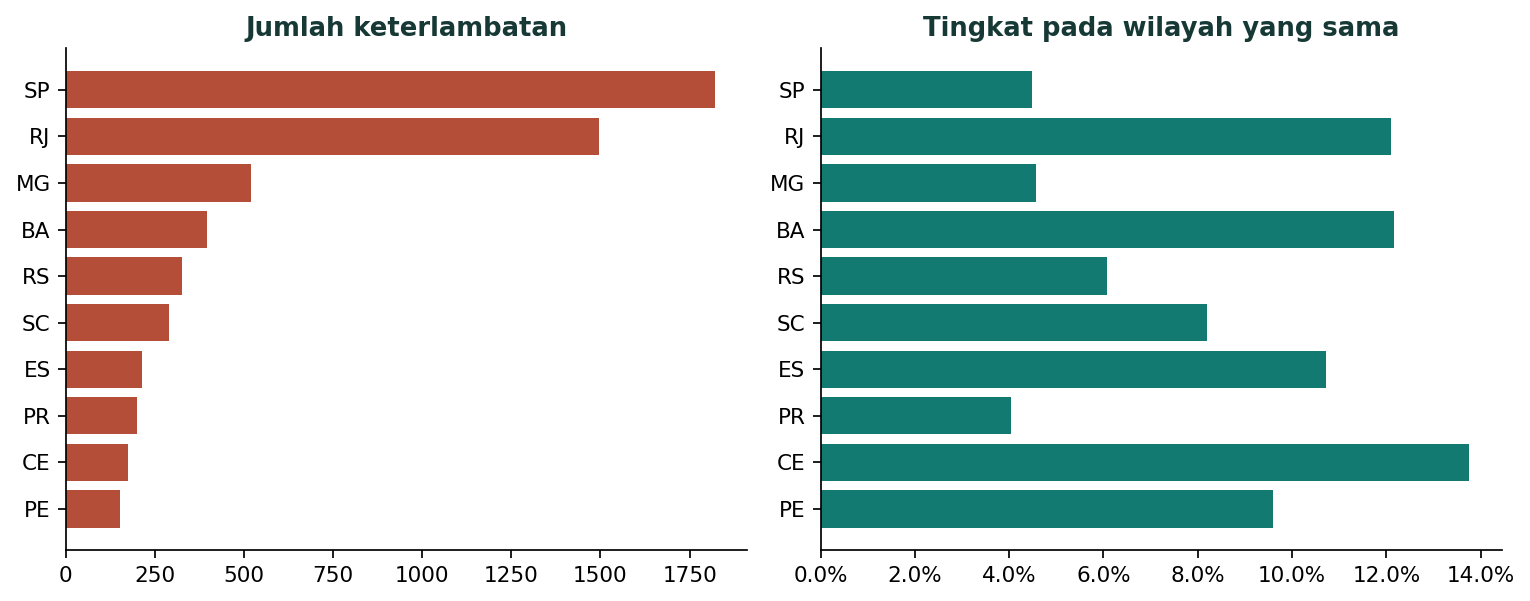

In [4]:
def segment(d, keys):
    g=d.groupby(keys,dropna=False).agg(eligible=('eligible','sum'),late=('late','sum'),late_brl=('late_brl','sum'))
    return g.assign(rate=g.late/g.eligible.replace(0,np.nan)).reset_index()
state=segment(orders,['state']).sort_values('late',ascending=False)
segments=segment(orders,['state','category'])
state.to_csv(out/'states.csv',index=False)
ranking=[]
for scope, d in [('full',segments),('core',segment(orders[window],['state','category']))]:
    for threshold in [50,100,250]:
        pool=d[d.eligible.ge(threshold)]
        for metric in ['late','rate','late_brl']:
            leaders=pool.sort_values([metric,'state','category'],ascending=[False,True,True]).head(8)
            ranking.append(leaders.assign(scope=scope,threshold=threshold,metric=metric,
                                          rank=range(1,len(leaders)+1)))
rank=pd.concat(ranking,ignore_index=True)
rank.to_csv(out/'priority.csv',index=False)
display(rank[(rank.scope=='full')&(rank.threshold==100)&(rank['rank']<=2)])
top=state.head(10)
fig,ax=plt.subplots(1,2,figsize=(10,4))
for a,col,color,title in [(ax[0],'late',rust,'Jumlah keterlambatan'),(ax[1],'rate',teal,'Tingkat pada wilayah yang sama')]:
    a.barh(top.state[::-1],top[col][::-1],color=color)
    a.set_title(title)
ax[1].xaxis.set_major_formatter(PercentFormatter(1))
save(fig,'03_state_priority')

## 4. Tahap pengiriman dan rating
Durasi menggunakan pasangan tahap yang lengkap dan berurutan. Rata-rata dan median dilaporkan karena durasi bisa menceng. Rating adalah rating terakhir per pesanan. Perbandingan rating rendah di dalam negara bagian membantu melihat apakah arah hubungan hanya berasal dari komposisi wilayah. Analisis ini deskriptif.

Audit kunci, rekonsiliasi uang dan pembanding periode lama lulus.


,pre_carrier_days_size,pre_carrier_days_mean,pre_carrier_days_median,pre_carrier_days_p90,post_carrier_days_size,post_carrier_days_mean,post_carrier_days_median,post_carrier_days_p90
late,,,,,,,,
0.0,89750,3.027495,2.150567,6.12324,89750,7.984706,6.946094,15.258506
1.0,6531,6.060952,3.497176,14.44728,6531,27.888557,26.198067,44.779595


,n,mean,low,coverage
late,,,,
0.0,89443,4.290386,0.092674,0.994518
1.0,6381,2.270491,0.624197,0.976584


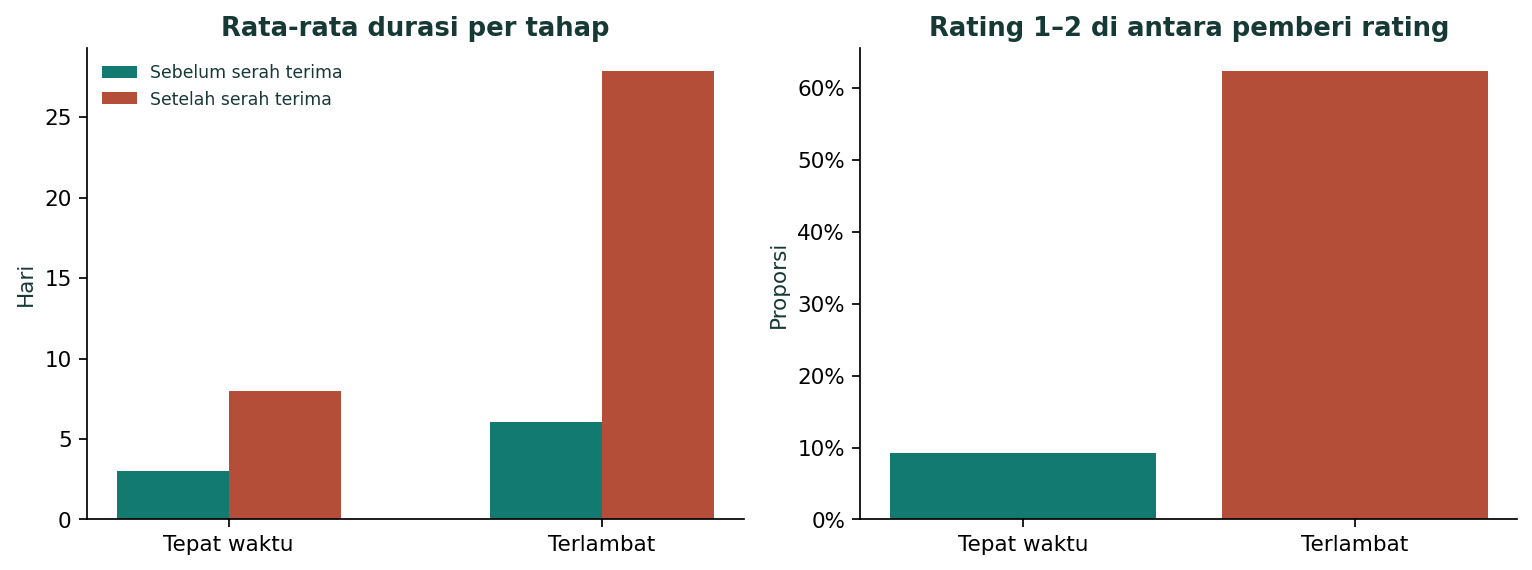

In [5]:
eligible=orders[orders.eligible.eq(1)]
phases=eligible.dropna(subset=['pre_carrier_days','post_carrier_days'])
phase=phases.groupby('late')[['pre_carrier_days','post_carrier_days']].agg(['size','mean','median',lambda x:x.quantile(.9)])
phase.columns=[f'{col}_{stat if stat!="<lambda_0>" else "p90"}' for col,stat in phase.columns]
phase.to_csv(out/'phases.csv')
ratings=eligible.dropna(subset=['review_score']).assign(low=lambda x:x.review_score.le(2))
review=ratings.groupby('late').agg(n=('review_score','size'),mean=('review_score','mean'),low=('low','mean'))
review['coverage']=review.n/eligible.groupby('late').size()
review.to_csv(out/'ratings.csv')
r=ratings.groupby(['state','late']).low.agg(['size','mean']).unstack()
r=r.dropna()
r=r[(r['size'][0]>=50)&(r['size'][1]>=50)]
r=r.assign(gap=r['mean'][1]-r['mean'][0])
r.to_csv(out/'ratings_within_state.csv')
display(phase)
display(review)
fig,ax=plt.subplots(1,2,figsize=(10,3.8))
pos=np.arange(2)
for i,col in enumerate(['pre_carrier_days_mean','post_carrier_days_mean']):
    ax[0].bar(pos+(i-.5)*.3,phase[col],width=.3,color=[teal,rust][i],
              label=['Sebelum serah terima','Setelah serah terima'][i])
ax[0].set(xticks=pos,xticklabels=['Tepat waktu','Terlambat'],ylabel='Hari',title='Rata-rata durasi per tahap')
ax[0].legend(frameon=False,fontsize=8)
ax[1].bar(['Tepat waktu','Terlambat'],review.low,color=[teal,rust])
ax[1].set(title='Rating 1–2 di antara pemberi rating',ylabel='Proporsi')
ax[1].yaxis.set_major_formatter(PercentFormatter(1))
save(fig,'04_stages_and_reviews')
total['reviews_states_qualified']=len(r)
total['reviews_states_positive_gap']=int((r.gap>0).sum())
total['phase']=phase.to_dict(orient='index')
total['reviews']=review.to_dict(orient='index')
(out/'metrics.json').write_text(json.dumps(total,indent=2))
print('Audit kunci, rekonsiliasi uang dan pembanding periode lama lulus.')

## 5. Penggunaan hasil
Gunakan volume dan nilai produk terkait untuk memilih antrean pemeriksaan. Tinjau waktu setelah serah terima menurut jalur dan kategori yang sebanding. Data historis tidak memuat identitas pengangkut dan penyebab insiden. Rating tersedia pada sebagian pesanan dan dapat dipengaruhi faktor di luar pengiriman. Peringkat kelompok dan angka penjualan sensitif terhadap kategori utama versus kategori item.